# COMP813 — Domain Shift Analysis

## Investigating Enron → CEAS-08 Distribution Differences

### Objective

The previous experiments showed substantial performance degradation
when models trained on Enron were evaluated on the unseen CEAS-08
dataset.

This notebook investigates measurable differences between the two
datasets that may help explain the observed cross-dataset performance
degradation.

The analysis focuses on:

- Class distribution
- Email length
- Vocabulary size
- Vocabulary overlap
- Out-of-vocabulary (OOV) rates
- BiLSTM unknown-token coverage
- Word-frequency characteristics

The analysis is descriptive and does not assume that any individual
dataset characteristic is the sole cause of the observed performance
difference.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import time

from collections import Counter

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
train_df = pd.read_csv(
    "enron_train.csv"
)

val_df = pd.read_csv(
    "enron_val.csv"
)

test_df = pd.read_csv(
    "enron_test.csv"
)

ceas_df = pd.read_csv(
    "ceas08_clean.csv"
)

print("Enron train:", train_df.shape)
print("Enron validation:", val_df.shape)
print("Enron test:", test_df.shape)
print("CEAS-08:", ceas_df.shape)

Enron train: (20596, 2)
Enron validation: (4414, 2)
Enron test: (4414, 2)
CEAS-08: (38964, 2)


In [4]:
X_enron = train_df["text"].astype(str)
y_enron = train_df["label"]

X_ceas = ceas_df["text"].astype(str)
y_ceas = ceas_df["label"]

print("Enron training emails:", len(X_enron))
print("CEAS-08 emails:", len(X_ceas))

Enron training emails: 20596
CEAS-08 emails: 38964


In [5]:
enron_class_counts = y_enron.value_counts().sort_index()
ceas_class_counts = y_ceas.value_counts().sort_index()

print("ENRON TRAIN")
print(enron_class_counts)

print("\nCEAS-08")
print(ceas_class_counts)

ENRON TRAIN
label
0    10831
1     9765
Name: count, dtype: int64

CEAS-08
label
0    17290
1    21674
Name: count, dtype: int64


In [6]:
enron_class_pct = (
    y_enron.value_counts(normalize=True)
    .sort_index()
    * 100
)

ceas_class_pct = (
    y_ceas.value_counts(normalize=True)
    .sort_index()
    * 100
)

print("ENRON TRAIN (%)")
print(enron_class_pct.round(2))

print("\nCEAS-08 (%)")
print(ceas_class_pct.round(2))

ENRON TRAIN (%)
label
0    52.59
1    47.41
Name: proportion, dtype: float64

CEAS-08 (%)
label
0    44.37
1    55.63
Name: proportion, dtype: float64


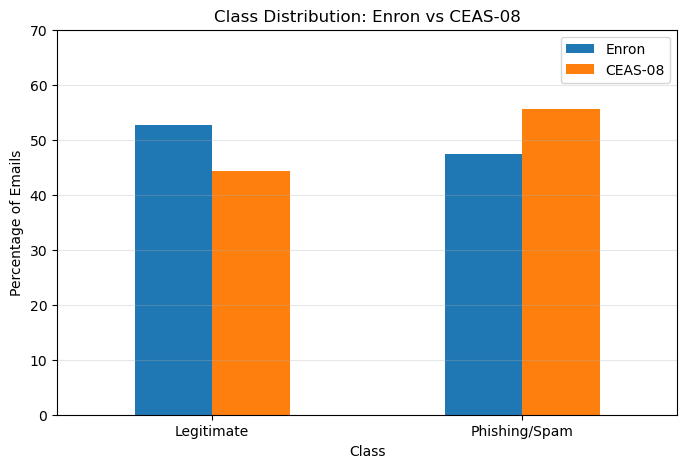

In [7]:
class_comparison = pd.DataFrame({
    "Enron": enron_class_pct,
    "CEAS-08": ceas_class_pct
})

class_comparison.index = [
    "Legitimate",
    "Phishing/Spam"
]

class_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Percentage of Emails")
plt.xlabel("Class")
plt.title("Class Distribution: Enron vs CEAS-08")

plt.xticks(rotation=0)
plt.ylim(0, 70)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [8]:
def tokenize_text(text):
    return re.findall(
        r"\b\w+\b",
        text.lower()
    )

In [9]:
sample = X_enron.iloc[0]

print(sample[:500])
print("\nTokens:")
print(tokenize_text(sample)[:30])

subject: fw : cancel pedricktown visit body: as outlined below , we will not bid on pedricktown and have therefore cancelled the " formal " site visit . - - - - - original message - - - - - from : heintzelman , pete sent : friday , november 02 , 2001 2 : 26 pm to : heintzelman , pete ; newlin , ross ; dobler , mark ; whitaker , rick ; clifford , douglas ; stevens , don cc : zisman , stuart ; miller , don ( asset mktg ) ; tricoli , carl ; davis , mark dana subject : re : cancel pedricktown visit 

Tokens:
['subject', 'fw', 'cancel', 'pedricktown', 'visit', 'body', 'as', 'outlined', 'below', 'we', 'will', 'not', 'bid', 'on', 'pedricktown', 'and', 'have', 'therefore', 'cancelled', 'the', 'formal', 'site', 'visit', 'original', 'message', 'from', 'heintzelman', 'pete', 'sent', 'friday']


In [10]:
enron_lengths = np.array([
    len(tokenize_text(text))
    for text in X_enron
])

ceas_lengths = np.array([
    len(tokenize_text(text))
    for text in X_ceas
])

print("ENRON")
print("Mean:", enron_lengths.mean())
print("Median:", np.median(enron_lengths))
print("Std:", enron_lengths.std())

print("\nCEAS-08")
print("Mean:", ceas_lengths.mean())
print("Median:", np.median(ceas_lengths))
print("Std:", ceas_lengths.std())

ENRON
Mean: 246.8671586715867
Median: 122.0
Std: 684.8544447788964

CEAS-08
Mean: 253.2157889333744
Median: 101.0
Std: 552.2675079710042


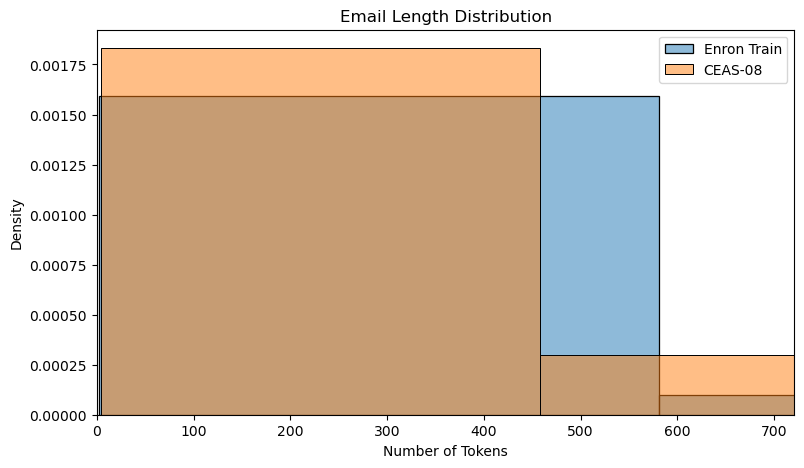

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    enron_lengths,
    bins=50,
    stat="density",
    alpha=0.5,
    label="Enron Train"
)

sns.histplot(
    ceas_lengths,
    bins=50,
    stat="density",
    alpha=0.5,
    label="CEAS-08"
)

plt.xlabel("Number of Tokens")
plt.ylabel("Density")
plt.title("Email Length Distribution")
plt.legend()

plt.xlim(
    0,
    np.percentile(
        np.concatenate([
            enron_lengths,
            ceas_lengths
        ]),
        95
    )
)

plt.show()

In [12]:
enron_vocab = set()

for text in X_enron:

    tokens = tokenize_text(text)

    enron_vocab.update(tokens)

print(
    "Enron unique vocabulary:",
    len(enron_vocab)
)

Enron unique vocabulary: 131063


In [13]:
ceas_vocab = set()

for text in X_ceas:

    tokens = tokenize_text(text)

    ceas_vocab.update(tokens)

print(
    "CEAS-08 unique vocabulary:",
    len(ceas_vocab)
)

CEAS-08 unique vocabulary: 186503


In [14]:
shared_vocab = (
    enron_vocab
    .intersection(ceas_vocab)
)

enron_only_vocab = (
    enron_vocab
    - ceas_vocab
)

ceas_only_vocab = (
    ceas_vocab
    - enron_vocab
)

print("Enron vocabulary:", len(enron_vocab))
print("CEAS vocabulary:", len(ceas_vocab))
print("Shared vocabulary:", len(shared_vocab))
print("Enron-only words:", len(enron_only_vocab))
print("CEAS-only words:", len(ceas_only_vocab))

Enron vocabulary: 131063
CEAS vocabulary: 186503
Shared vocabulary: 42683
Enron-only words: 88380
CEAS-only words: 143820


In [15]:
enron_coverage = (
    len(shared_vocab)
    / len(enron_vocab)
    * 100
)

ceas_coverage = (
    len(shared_vocab)
    / len(ceas_vocab)
    * 100
)

print(
    f"Shared vocabulary as % of Enron vocabulary: "
    f"{enron_coverage:.2f}%"
)

print(
    f"CEAS vocabulary covered by Enron: "
    f"{ceas_coverage:.2f}%"
)

Shared vocabulary as % of Enron vocabulary: 32.57%
CEAS vocabulary covered by Enron: 22.89%


In [16]:
vocabulary_stats = pd.DataFrame({
    "Metric": [
        "Enron unique vocabulary",
        "CEAS-08 unique vocabulary",
        "Shared vocabulary",
        "Enron-only vocabulary",
        "CEAS-only vocabulary",
        "Shared vocabulary (% of Enron)",
        "CEAS vocabulary covered by Enron (%)"
    ],

    "Value": [
        len(enron_vocab),
        len(ceas_vocab),
        len(shared_vocab),
        len(enron_only_vocab),
        len(ceas_only_vocab),
        enron_coverage,
        ceas_coverage
    ]
})

vocabulary_stats

,Metric,Value
0,Enron unique vocabulary,131063.000000
1,CEAS-08 unique vocabulary,186503.000000
2,Shared vocabulary,42683.000000
3,Enron-only vocabulary,88380.000000
4,CEAS-only vocabulary,143820.000000
5,Shared vocabulary (% of Enron),32.566781
6,CEAS vocabulary covered by Enron (%),22.885959


In [17]:
vocabulary_stats.to_csv(
    "domain_shift_vocabulary_statistics.csv",
    index=False
)

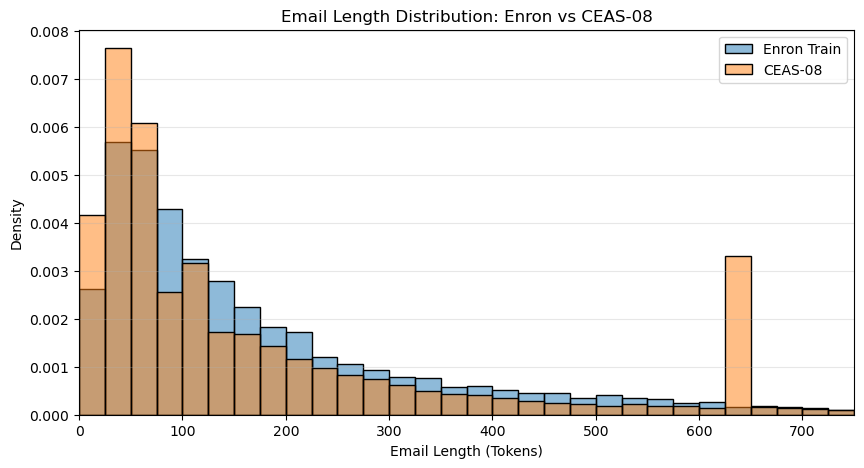

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    enron_lengths,
    bins=np.arange(0, 751, 25),
    stat="density",
    alpha=0.5,
    label="Enron Train"
)

sns.histplot(
    ceas_lengths,
    bins=np.arange(0, 751, 25),
    stat="density",
    alpha=0.5,
    label="CEAS-08"
)

plt.xlim(0, 750)
plt.xlabel("Email Length (Tokens)")
plt.ylabel("Density")
plt.title("Email Length Distribution: Enron vs CEAS-08")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

## 4. Token-Level Out-of-Vocabulary Analysis

Vocabulary overlap measures the proportion of unique words shared
between datasets.

However, unique vocabulary overlap does not account for how
frequently individual words appear.

This section measures the proportion of CEAS-08 token occurrences
that are absent from the Enron training vocabulary.

The analysis is subsequently repeated using the actual restricted
vocabulary used by the BiLSTM model.

In [19]:
# Count token occurrences in CEAS-08

ceas_token_counts = Counter()

for text in X_ceas:
    ceas_token_counts.update(
        tokenize_text(text)
    )

total_ceas_tokens = sum(
    ceas_token_counts.values()
)

# Count occurrences of tokens unseen in Enron

unknown_token_count = sum(
    frequency
    for token, frequency in ceas_token_counts.items()
    if token not in enron_vocab
)

known_token_count = (
    total_ceas_tokens - unknown_token_count
)

oov_rate = (
    unknown_token_count / total_ceas_tokens
) * 100

print("CEAS-08 TOKEN COVERAGE")
print("=" * 50)

print("Total token occurrences:", total_ceas_tokens)
print("Known token occurrences:", known_token_count)
print("Unknown token occurrences:", unknown_token_count)

print(f"\nToken-level OOV rate: {oov_rate:.2f}%")
print(f"Token coverage: {100 - oov_rate:.2f}%")

CEAS-08 TOKEN COVERAGE
Total token occurrences: 9866300
Known token occurrences: 9031606
Unknown token occurrences: 834694

Token-level OOV rate: 8.46%
Token coverage: 91.54%


In [20]:
import json

with open(
    "../models/bilstm_vocabulary.json",
    "r"
) as f:
    bilstm_vocab = json.load(f)

print(
    "BiLSTM vocabulary size:",
    len(bilstm_vocab)
)

BiLSTM vocabulary size: 50000


In [21]:
bilstm_vocab_set = set(
    bilstm_vocab.keys()
)

bilstm_unknown_count = sum(
    frequency
    for token, frequency in ceas_token_counts.items()
    if token not in bilstm_vocab_set
)

bilstm_known_count = (
    total_ceas_tokens - bilstm_unknown_count
)

bilstm_oov_rate = (
    bilstm_unknown_count / total_ceas_tokens
) * 100

print("BiLSTM — CEAS-08 VOCABULARY COVERAGE")
print("=" * 50)

print("Total CEAS tokens:", total_ceas_tokens)
print("Known tokens:", bilstm_known_count)
print("Unknown tokens:", bilstm_unknown_count)

print(f"\nBiLSTM OOV rate: {bilstm_oov_rate:.2f}%")
print(
    f"BiLSTM token coverage: "
    f"{100 - bilstm_oov_rate:.2f}%"
)

BiLSTM — CEAS-08 VOCABULARY COVERAGE
Total CEAS tokens: 9866300
Known tokens: 8881181
Unknown tokens: 985119

BiLSTM OOV rate: 9.98%
BiLSTM token coverage: 90.02%


In [22]:
coverage_results = pd.DataFrame({
    "Representation": [
        "Complete Enron Vocabulary",
        "BiLSTM Vocabulary"
    ],

    "Known Tokens (%)": [
        100 - oov_rate,
        100 - bilstm_oov_rate
    ],

    "Unknown Tokens (%)": [
        oov_rate,
        bilstm_oov_rate
    ]
})

coverage_results.round(2)

,Representation,Known Tokens (%),Unknown Tokens (%)
0,Complete Enron Vocabulary,91.54,8.46
1,BiLSTM Vocabulary,90.02,9.98


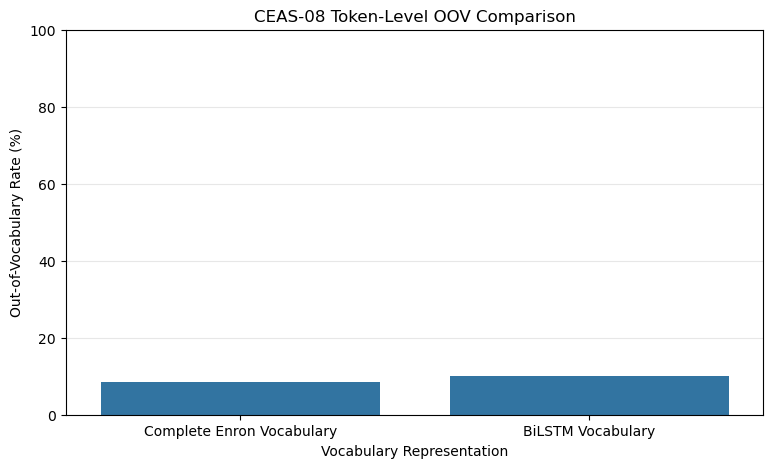

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=coverage_results,
    x="Representation",
    y="Unknown Tokens (%)"
)

plt.ylabel("Out-of-Vocabulary Rate (%)")
plt.xlabel("Vocabulary Representation")
plt.title("CEAS-08 Token-Level OOV Comparison")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [24]:
effective_total_tokens = 0
effective_unknown_tokens = 0

for text in X_ceas:

    tokens = tokenize_text(text)

    # Same truncation used by the BiLSTM
    tokens = tokens[:500]

    effective_total_tokens += len(tokens)

    effective_unknown_tokens += sum(
        1
        for token in tokens
        if token not in bilstm_vocab_set
    )

effective_oov_rate = (
    effective_unknown_tokens /
    effective_total_tokens
) * 100

effective_coverage = (
    100 - effective_oov_rate
)

print("BiLSTM EFFECTIVE CEAS-08 VOCABULARY COVERAGE")
print("=" * 55)

print(
    "Tokens actually processed:",
    effective_total_tokens
)

print(
    "Unknown tokens:",
    effective_unknown_tokens
)

print(
    f"\nEffective OOV rate: "
    f"{effective_oov_rate:.2f}%"
)

print(
    f"Effective token coverage: "
    f"{effective_coverage:.2f}%"
)

BiLSTM EFFECTIVE CEAS-08 VOCABULARY COVERAGE
Tokens actually processed: 6951454
Unknown tokens: 645772

Effective OOV rate: 9.29%
Effective token coverage: 90.71%


In [25]:
def calculate_oov_by_class(
    dataframe,
    vocab_set,
    max_length=None
):

    results = []

    for label in sorted(dataframe["label"].unique()):

        subset = dataframe[
            dataframe["label"] == label
        ]

        total_tokens = 0
        unknown_tokens = 0

        for text in subset["text"].astype(str):

            tokens = tokenize_text(text)

            if max_length is not None:
                tokens = tokens[:max_length]

            total_tokens += len(tokens)

            unknown_tokens += sum(
                1
                for token in tokens
                if token not in vocab_set
            )

        oov_rate = (
            unknown_tokens /
            total_tokens
        ) * 100

        results.append({
            "Label": label,
            "Total Tokens": total_tokens,
            "Unknown Tokens": unknown_tokens,
            "OOV Rate (%)": oov_rate
        })

    return pd.DataFrame(results)

In [26]:
oov_by_class = calculate_oov_by_class(
    ceas_df,
    bilstm_vocab_set,
    max_length=500
)

oov_by_class

,Label,Total Tokens,Unknown Tokens,OOV Rate (%)
0,0,4380534,443208,10.117671
1,1,2570920,202564,7.879047


## 5. Sequence Truncation Analysis

The BiLSTM processes a maximum of 500 tokens per email. Emails
longer than this limit are truncated before classification.

This section measures how frequently truncation occurs in CEAS-08
and whether truncation differs between legitimate and phishing/spam
emails.

In [28]:
MAX_SEQUENCE_LENGTH = 500

ceas_token_lengths = np.array([
    len(tokenize_text(text))
    for text in X_ceas
])

truncated_mask = (
    ceas_token_lengths > MAX_SEQUENCE_LENGTH
)

num_truncated = truncated_mask.sum()
num_total = len(ceas_token_lengths)

truncation_rate = (
    num_truncated / num_total
) * 100

print("CEAS-08 SEQUENCE TRUNCATION")
print("=" * 50)

print("Total emails:", num_total)
print("Emails longer than 500 tokens:", num_truncated)

print(
    f"Truncation rate: {truncation_rate:.2f}%"
)

CEAS-08 SEQUENCE TRUNCATION
Total emails: 38964
Emails longer than 500 tokens: 6188
Truncation rate: 15.88%


In [29]:
ceas_truncation_by_class = []

for label in sorted(ceas_df["label"].unique()):

    subset = ceas_df[
        ceas_df["label"] == label
    ]

    lengths = np.array([
        len(tokenize_text(text))
        for text in subset["text"].astype(str)
    ])

    truncated = (
        lengths > MAX_SEQUENCE_LENGTH
    ).sum()

    total = len(lengths)

    rate = (
        truncated / total
    ) * 100

    ceas_truncation_by_class.append({
        "Label": label,
        "Total Emails": total,
        "Truncated Emails": truncated,
        "Truncation Rate (%)": rate
    })

truncation_results = pd.DataFrame(
    ceas_truncation_by_class
)

truncation_results

,Label,Total Emails,Truncated Emails,Truncation Rate (%)
0,0,17290,3142,18.172354
1,1,21674,3046,14.053705


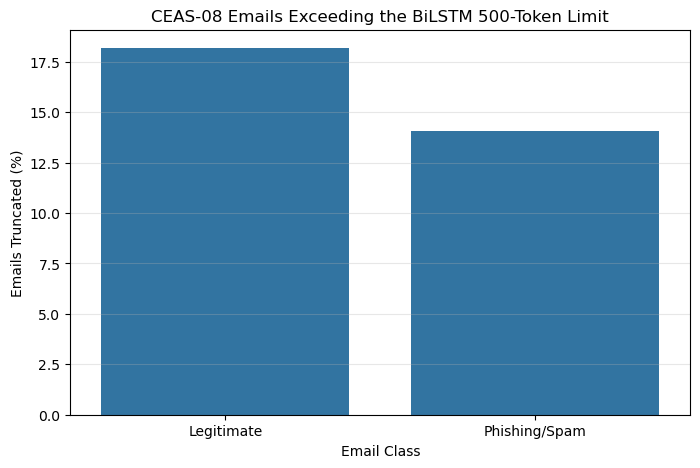

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=truncation_results,
    x="Label",
    y="Truncation Rate (%)"
)

plt.xticks(
    [0, 1],
    ["Legitimate", "Phishing/Spam"]
)

plt.ylabel("Emails Truncated (%)")
plt.xlabel("Email Class")
plt.title(
    "CEAS-08 Emails Exceeding the BiLSTM 500-Token Limit"
)

plt.grid(axis="y", alpha=0.3)

plt.show()

In [31]:
total_original_tokens = ceas_token_lengths.sum()

total_processed_tokens = np.minimum(
    ceas_token_lengths,
    MAX_SEQUENCE_LENGTH
).sum()

tokens_discarded = (
    total_original_tokens -
    total_processed_tokens
)

token_discard_rate = (
    tokens_discarded /
    total_original_tokens
) * 100

print("TOKEN LOSS DUE TO TRUNCATION")
print("=" * 50)

print(
    "Original CEAS-08 tokens:",
    total_original_tokens
)

print(
    "Tokens processed by BiLSTM:",
    total_processed_tokens
)

print(
    "Tokens discarded:",
    tokens_discarded
)

print(
    f"\nToken discard rate: "
    f"{token_discard_rate:.2f}%"
)

TOKEN LOSS DUE TO TRUNCATION
Original CEAS-08 tokens: 9866300
Tokens processed by BiLSTM: 6951454
Tokens discarded: 2914846

Token discard rate: 29.54%


In [32]:
token_loss_by_class = []

for label in sorted(ceas_df["label"].unique()):

    subset = ceas_df[
        ceas_df["label"] == label
    ]

    original_tokens = 0
    processed_tokens = 0

    for text in subset["text"].astype(str):

        tokens = tokenize_text(text)

        original_tokens += len(tokens)

        processed_tokens += min(
            len(tokens),
            MAX_SEQUENCE_LENGTH
        )

    discarded_tokens = (
        original_tokens -
        processed_tokens
    )

    discard_rate = (
        discarded_tokens /
        original_tokens
    ) * 100

    token_loss_by_class.append({
        "Label": label,
        "Original Tokens": original_tokens,
        "Processed Tokens": processed_tokens,
        "Discarded Tokens": discarded_tokens,
        "Token Discard Rate (%)": discard_rate
    })

token_loss_results = pd.DataFrame(
    token_loss_by_class
)

token_loss_results

,Label,Original Tokens,Processed Tokens,Discarded Tokens,Token Discard Rate (%)
0,0,6873437,4380534,2492903,36.268653
1,1,2992863,2570920,421943,14.098307


In [33]:
token_loss_display = token_loss_results.copy()

token_loss_display[
    "Token Discard Rate (%)"
] = token_loss_display[
    "Token Discard Rate (%)"
].round(2)

token_loss_display

,Label,Original Tokens,Processed Tokens,Discarded Tokens,Token Discard Rate (%)
0,0,6873437,4380534,2492903,36.27
1,1,2992863,2570920,421943,14.10


## 6. Domain Shift Summary

The domain-shift analysis identified several measurable differences
between the Enron training corpus and the unseen CEAS-08 corpus.

CEAS-08 contains substantially more unique vocabulary than the Enron
training data. Only 22.89% of unique CEAS-08 tokens were also present
in the Enron vocabulary. However, frequency-weighted token coverage
was considerably higher, with 91.54% of CEAS-08 token occurrences
covered by the complete Enron vocabulary.

The restricted vocabulary used by the BiLSTM provided 90.02% token
coverage across the full CEAS-08 corpus. Considering only the first
500 tokens processed by the BiLSTM, the effective OOV rate was 9.29%.

Vocabulary coverage differed between classes. The effective OOV rate
was 10.12% for legitimate emails compared with 7.88% for phishing/spam
emails.

Sequence truncation was another substantial characteristic of the
domain shift. 15.88% of CEAS-08 emails exceeded the BiLSTM's 500-token
sequence limit. Overall, 29.54% of CEAS-08 token occurrences were
discarded.

The class-level analysis revealed a substantial difference in token
discard rates. 36.27% of tokens from legitimate CEAS-08 emails were
discarded compared with 14.10% from phishing/spam emails.

These results identify vocabulary mismatch and sequence truncation
as important measurable characteristics of the cross-dataset
setting. The higher OOV and truncation rates observed for legitimate
emails are also consistent with the BiLSTM's large number of
legitimate-to-phishing false positives. However, these analyses do
not establish causality. The next experiment therefore examines
individual classification errors to determine whether these
characteristics are associated with specific model mistakes.